In [3]:
import pandas as pd
apple = pd.read_csv("../data/processed/apple_stock_cleaned.csv")
apple["Date"] = pd.to_datetime(apple["Date"])
apple.head()

,Date,Close,High,Low,Open,Volume
0,2021-08-24,145.935043,147.144509,145.476618,145.769232,48606400
1,2021-08-25,144.706055,146.617789,144.159849,146.120340,58991300
2,2021-08-26,143.906250,145.447338,143.876990,144.696313,48597200
3,2021-08-27,144.940140,145.086439,143.213729,143.847714,55802400
4,2021-08-30,149.348801,149.709698,144.949883,145.330277,90956700


In [6]:
# Calculate the 7-day moving average to smooth short-term price fluctuations
apple["MA7"] = apple["Close"].rolling(window=7).mean()

# Calculate the 21-day moving average to show the longer-term price trend
apple["MA21"] = apple["Close"].rolling(window=21).mean()

# A moving average is the average closing price over a certain number of previous days.
# Instead of looking at the price for just one day, it combines several days together to make the graph smoother.
# This helps reduce daily ups and downs and makes it easier to see the overall trend. 
# In this notebook, I used a 7-day moving average to look at short-term changes and a 21-day moving average to understand the longer-term trend.

apple[["Close","MA7","MA21"]].head(25)

,Close,MA7,MA21
0,145.935043,NaN,NaN
1,144.706055,NaN,NaN
2,143.906250,NaN,NaN
3,144.940140,NaN,NaN
4,149.348801,NaN,NaN
5,148.090561,NaN,NaN
6,148.753830,146.525811,NaN
7,149.865768,147.087343,NaN
8,150.499756,147.915015,NaN
9,152.830917,149.189968,NaN


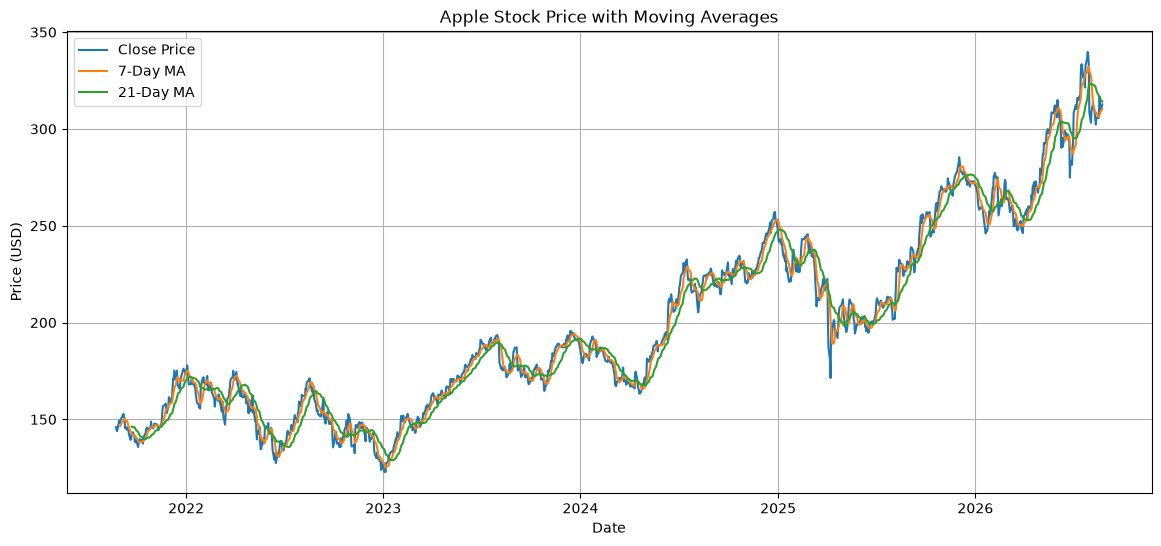

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))
plt.plot(apple["Date"], apple["Close"], label="Close Price")
plt.plot(apple["Date"], apple["MA7"], label="7-Day MA")
plt.plot(apple["Date"], apple["MA21"], label="21-Day MA")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.title("Apple Stock Price with Moving Averages")

plt.legend()
plt.grid()
plt.show()

# Observations
# The closing price fluctuates every day, showing normal market volatility.
# The 7-day moving average follows the closing price closely while smoothing out small daily changes.
# The 21-day moving average is smoother than the 7-day moving average because it uses more previous data points.
# When the stock price changes quickly, the 7-day moving average responds faster, while the 21-day moving average changes more gradually.
# Overall, the moving averages make it easier to identify Apple's upward trend over time by reducing daily price fluctuations.

In [9]:

apple.to_csv("../data/processed/apple_stock_cleaned.csv", index=False)